In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ast

# Loading Files

In [2]:
# Read in woke and not woke AppIDs
wokeGames = pd.read_csv("Data/wokeGames.csv")
wokeGames.drop(columns=["Unnamed: 0"], inplace=True)
notWokeGames = pd.read_csv("Data/notWokeGames.csv")
notWokeGames.drop(columns=["Unnamed: 0"], inplace=True)


In [3]:
# Read in steam file
steam = pd.read_csv("Data/games_march2025_cleaned.csv")

# drop a LOT of irrelevant data
steam = steam.drop(columns=["about_the_game", "release_date", "short_description",
                            "detailed_description", "support_url", "support_email",
                            "website", "reviews", "metacritic_score", "metacritic_url",
                            "notes", "score_rank", "header_image", "packages", "developers", "publishers",
                            "screenshots", "movies", "estimated_owners", "name"]) #NEED TO WRITE SOMETHING FOR TAGS

# user score value is all 0 in dataset, so just calculate it
steam["user_score"] = steam["positive"] / (steam["negative"] + steam["positive"]) # maybe needed??

# add woke information
steam["isWoke"] = steam["appid"].isin(wokeGames["0"])
steam["isNotWoke"] = steam["appid"].isin(notWokeGames["0"])



# Preprocessing!!!

In [4]:
# create dummy variables from a column that is currently a list string
def dummyVariable(name_of_feature):
    global steam
    # use python text to list thingy thing
    steam["temp"] = steam[name_of_feature].apply(ast.literal_eval)
    exploded_languages = steam["temp"].explode()
    # turn many values of the same langauge from the explosion into "max", whether it supports that language or not
    dummies_languages = pd.get_dummies(exploded_languages).groupby(level=0).max()
    dummies_languages.columns += "_" + name_of_feature
    steam = pd.concat([steam, dummies_languages], axis=1)
    steam.drop(columns=["temp", name_of_feature], inplace=True)

# make dummy variables for different columns
dummyVariable("supported_languages")
dummyVariable("full_audio_languages")
dummyVariable("categories")
dummyVariable("genres")
dummyVariable("tags")


# EDA!!!!

In [5]:
# number of is woke and is not woke
print(steam["isWoke"].sum())
print(steam["isNotWoke"].sum())

# create dataset for specifically curated
steam_curated_woke = steam.loc[steam["isWoke"] == True]
steam_curated_notwoke = steam.loc[steam["isNotWoke"] == True]
steam_curated = pd.concat([steam_curated_woke, steam_curated_notwoke], axis=0)
print(steam_curated.info())
print(steam_curated.head())

907
519
<class 'pandas.DataFrame'>
Index: 1426 entries, 0 to 80684
Columns: 762 entries, appid to e-sports_tags
dtypes: bool(743), float64(2), int64(17)
memory usage: 1.2 MB
None
    appid  required_age  price  dlc_count  windows    mac  linux  \
0     730             0   0.00          1     True  False   True   
4  359550            17   3.99          9     True  False  False   
5     440             0   0.00          1     True  False   True   
6  105600             0   9.99          2     True   True   True   
8    4000             0   5.99          0     True   True   True   

   achievements  recommendations  user_score  ...  Well-Written_tags  \
0             1          4401572    0.868255  ...              False   
4             0          1165929    0.840691  ...              False   
5           520            41587    0.894771  ...              False   
6           115          1098792    0.975015  ...              False   
8            29           984713    0.967880  ...   

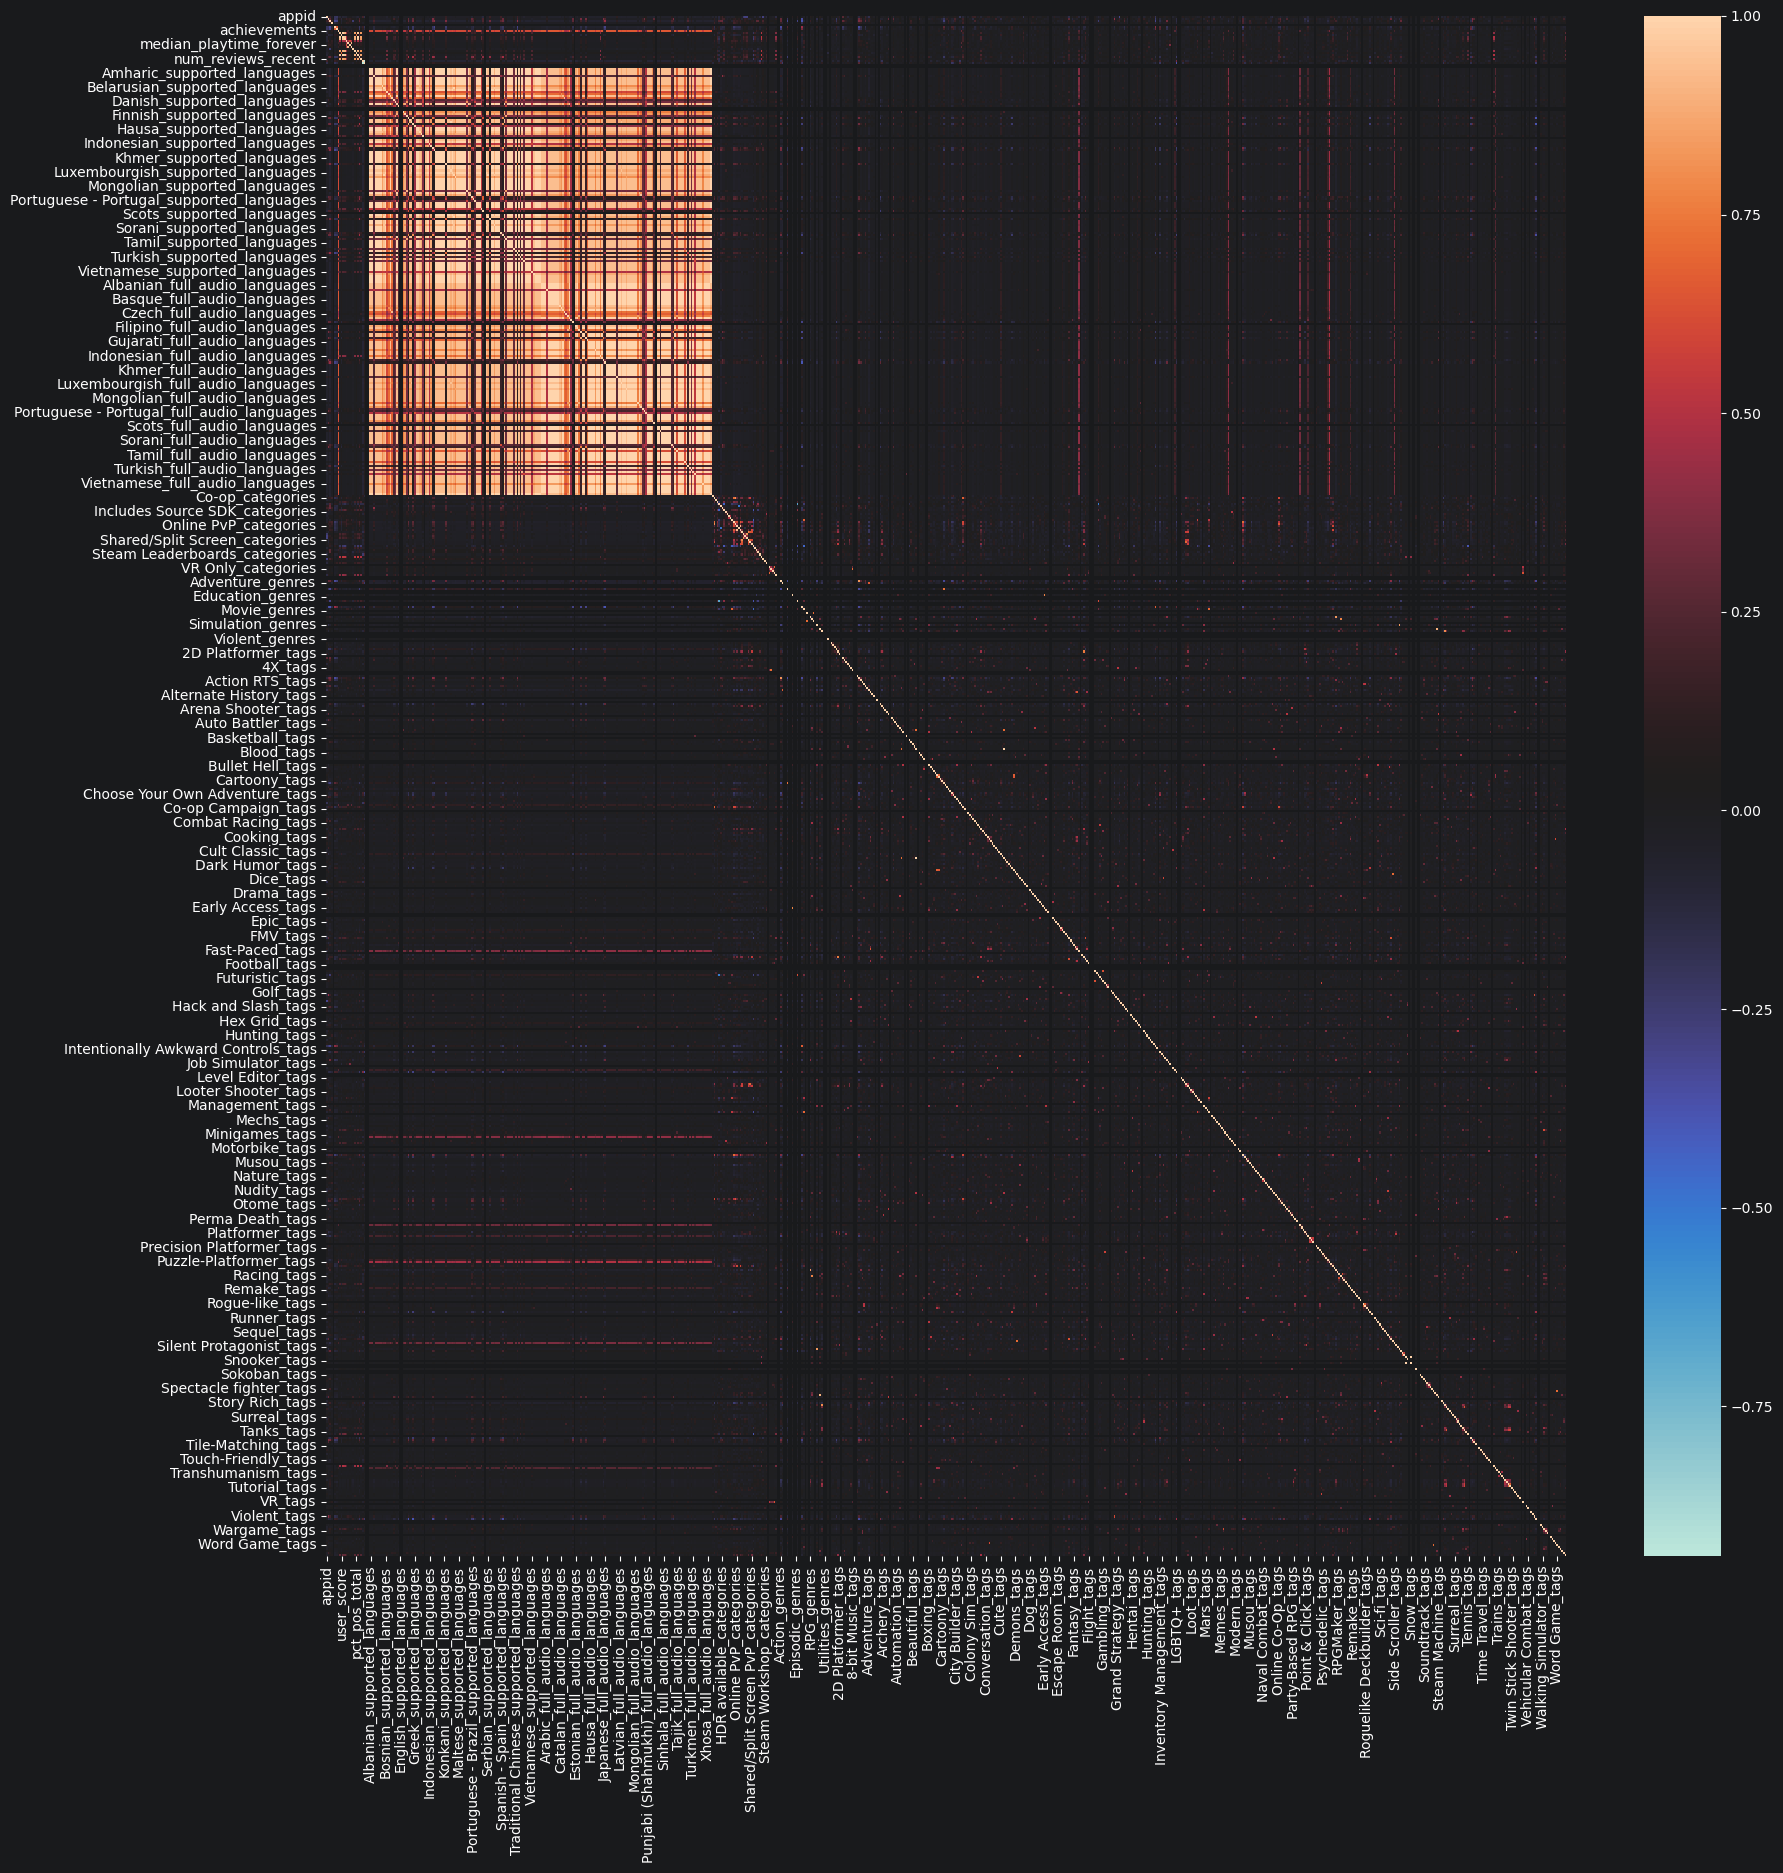

In [6]:
# creat correlation matrix ( to take a look at it)
correlation_matrix = steam_curated.corr()
# create csv since it's easier to read that way
correlation_matrix.to_csv("correlation.csv")
plt.figure(figsize=(20,20))
sns.heatmap(correlation_matrix, fmt="g", cmap="icefire")
plt.show()

# Creating a model????!!!!